# ApisTox 蜜蜂急性毒性分类

## 03 模型训练与评价

本阶段读取已经完成质量检查的分子描述符和 Morgan 指纹，
建立蜜蜂急性毒性二分类模型。

标签定义：

- `label = 0`：无毒
- `label = 1`：有毒

第一阶段采用随机分层训练集/测试集划分，确保两类标签比例基本一致。
在完全相同的数据划分下，比较以下模型：

1. 逻辑回归
2. 随机森林
3. 多层感知机（MLP）

并分别比较：

1. 10个可解释二维分子描述符
2. 2048位 Morgan 分子指纹

模型评价不只使用准确率，还将关注有毒类别的 Recall、Precision、
PR-AUC、ROC-AUC、MCC、Balanced Accuracy 和混淆矩阵。

所有需要从数据中学习的预处理步骤都只在训练数据上拟合，
避免数据泄漏。模型结果表示预测关联，不代表分子结构与蜜蜂毒性之间
存在直接的生物学因果关系。

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# 设置可重复使用的随机种子
RANDOM_STATE = 42

# 特征文件所在文件夹
processed_data_directory = Path("processed_data")

# 三个文件的完整路径
metadata_path = (
    processed_data_directory / "sample_metadata.csv"
)

descriptor_path = (
    processed_data_directory / "descriptor_features.csv"
)

morgan_path = (
    processed_data_directory / "morgan_features.csv"
)

# 确认文件确实存在
assert metadata_path.exists(), f"找不到文件：{metadata_path}"
assert descriptor_path.exists(), f"找不到文件：{descriptor_path}"
assert morgan_path.exists(), f"找不到文件：{morgan_path}"

# 读取三个文件
metadata = pd.read_csv(metadata_path)
descriptor_features = pd.read_csv(descriptor_path)
morgan_features = pd.read_csv(morgan_path)

print("样本信息表维度：", metadata.shape)
print("描述符表维度：", descriptor_features.shape)
print("Morgan指纹表维度：", morgan_features.shape)

样本信息表维度： (1035, 8)
描述符表维度： (1035, 11)
Morgan指纹表维度： (1035, 2049)


In [2]:
# 将 sample_id 设置为每张表的行索引
metadata_indexed = (
    metadata
    .set_index("sample_id")
    .sort_index()
)

descriptor_indexed = (
    descriptor_features
    .set_index("sample_id")
    .sort_index()
)

morgan_indexed = (
    morgan_features
    .set_index("sample_id")
    .sort_index()
)

# 检查 sample_id 是否唯一
assert metadata_indexed.index.is_unique
assert descriptor_indexed.index.is_unique
assert morgan_indexed.index.is_unique

# 检查三张表的 sample_id 及其顺序是否完全一致
assert metadata_indexed.index.equals(
    descriptor_indexed.index
)

assert metadata_indexed.index.equals(
    morgan_indexed.index
)

# 定义两套模型输入特征
X_descriptors = descriptor_indexed.copy()
X_morgan = morgan_indexed.copy()

# 定义需要预测的标签
y = metadata_indexed["label"].astype(int).copy()

# 基本质量检查
assert X_descriptors.isna().sum().sum() == 0
assert X_morgan.isna().sum().sum() == 0
assert y.isna().sum() == 0
assert set(y.unique()) == {0, 1}

print("描述符特征矩阵：", X_descriptors.shape)
print("Morgan指纹矩阵：", X_morgan.shape)
print("标签向量：", y.shape)

print("\n标签数量：")
print(y.value_counts().sort_index())

print("\n标签比例：")
print(
    y.value_counts(
        normalize=True
    ).sort_index().round(4)
)

描述符特征矩阵： (1035, 10)
Morgan指纹矩阵： (1035, 2048)
标签向量： (1035,)

标签数量：
label
0    739
1    296
Name: count, dtype: int64

标签比例：
label
0    0.714
1    0.286
Name: proportion, dtype: float64


## 3. 随机分层训练集与测试集划分

使用 80% 数据作为训练集，20% 数据作为最终测试集。

由于有毒类别约占 28.6%，划分时使用标签分层，保证训练集和测试集
中的类别比例与完整数据集基本一致。

数据划分只生成一次，两套分子结构表示使用完全相同的训练样本和
测试样本。测试集在模型选择、预处理拟合和参数调整过程中保持隔离。

In [3]:
from sklearn.model_selection import train_test_split

# 取得所有样本编号
all_sample_ids = y.index.to_numpy()

# 只划分一次 sample_id
train_ids, test_ids = train_test_split(
    all_sample_ids,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# 排序只是为了后续查看方便
train_ids = np.sort(train_ids)
test_ids = np.sort(test_ids)

# 根据相同的 sample_id 分别提取两套特征
X_descriptors_train = X_descriptors.loc[train_ids]
X_descriptors_test = X_descriptors.loc[test_ids]

X_morgan_train = X_morgan.loc[train_ids]
X_morgan_test = X_morgan.loc[test_ids]

# 提取对应标签
y_train = y.loc[train_ids]
y_test = y.loc[test_ids]

# 基本划分检查
assert len(set(train_ids) & set(test_ids)) == 0
assert len(train_ids) + len(test_ids) == len(y)

assert X_descriptors_train.index.equals(y_train.index)
assert X_descriptors_test.index.equals(y_test.index)
assert X_morgan_train.index.equals(y_train.index)
assert X_morgan_test.index.equals(y_test.index)

# 汇总类别分布
split_summary = pd.DataFrame(
    {
        "样本数": [
            len(y_train),
            len(y_test)
        ],
        "无毒数量": [
            (y_train == 0).sum(),
            (y_test == 0).sum()
        ],
        "有毒数量": [
            (y_train == 1).sum(),
            (y_test == 1).sum()
        ],
        "有毒比例_%": [
            (y_train == 1).mean() * 100,
            (y_test == 1).mean() * 100
        ]
    },
    index=[
        "训练集",
        "测试集"
    ]
)

split_summary.round(2)

,样本数,无毒数量,有毒数量,有毒比例_%
训练集,828,591,237,28.62
测试集,207,148,59,28.50


In [4]:
# 为每个化合物的 Morgan 指纹生成审查编号
fingerprint_hashes = pd.util.hash_pandas_object(
    X_morgan,
    index=False
)

# 分别取得训练集和测试集中的指纹编号
train_fingerprint_hashes = set(
    fingerprint_hashes.loc[train_ids]
)

test_fingerprint_hashes = set(
    fingerprint_hashes.loc[test_ids]
)

# 找出同时出现在训练集和测试集中的指纹
shared_fingerprint_hashes = (
    train_fingerprint_hashes
    & test_fingerprint_hashes
)

print(
    "同时出现在训练集和测试集中的相同指纹组数：",
    len(shared_fingerprint_hashes)
)

# 如果存在跨数据集的相同指纹，显示对应化合物
if len(shared_fingerprint_hashes) > 0:

    shared_fingerprint_mask = (
        fingerprint_hashes.isin(
            shared_fingerprint_hashes
        )
    )

    shared_fingerprint_records = (
        metadata_indexed.loc[
            shared_fingerprint_mask,
            [
                "name",
                "CAS",
                "SMILES",
                "label",
                "fragment_count"
            ]
        ]
        .copy()
    )

    # 标记每条记录属于训练集还是测试集
    shared_fingerprint_records["数据集"] = np.where(
        shared_fingerprint_records.index.isin(
            train_ids
        ),
        "训练集",
        "测试集"
    )

    # 加入指纹编号，便于识别同一组
    shared_fingerprint_records["fingerprint_hash"] = (
        fingerprint_hashes.loc[
            shared_fingerprint_mask
        ]
    )

    display(
        shared_fingerprint_records.sort_values(
            [
                "fingerprint_hash",
                "数据集"
            ]
        )
    )

同时出现在训练集和测试集中的相同指纹组数： 2


,name,CAS,SMILES,label,fragment_count,数据集,fingerprint_hash
sample_id,,,,,,,
84,Myristyl alcohol,112-72-1,CCCCCCCCCCCCCCO,0,1,测试集,877954270575632454
53,1-decanol,112-30-1,CCCCCCCCCCO,0,1,训练集,877954270575632454
975,Prochloraz manganese chloride complex,75747-77-2,CCCN(CCOc1c(Cl)cc(Cl)cc1Cl)C(=O)n1ccnc1.CCCN(C...,0,5,测试集,15685814701438206725
895,Prochloraz manganese complex (Ref: BTS 46828),69192-23-0,CCCN(CCOc1c(Cl)cc(Cl)cc1Cl)C(=O)n1ccnc1.CCCN(C...,0,3,训练集,15685814701438206725


### 相同指纹分组处理

初始随机分层划分中，有 2 组完全相同的 Morgan 指纹同时出现在
训练集和测试集。

为避免相同结构表示跨越两个数据集，最终随机基线使用分层分组划分：
在尽量保持标签比例一致的同时，将相同 Morgan 指纹的记录分配至
同一数据子集。

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

# 确认同一指纹组内不存在标签冲突
fingerprint_label_check = pd.DataFrame(
    {
        "fingerprint_hash": fingerprint_hashes,
        "label": y
    }
)

assert (
    fingerprint_label_check
    .groupby("fingerprint_hash")["label"]
    .nunique()
    .max()
    == 1
)

# 创建5折分层分组划分器
# 取其中1折作为约20%的最终测试集
group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 划分器要求提供X，这里只需要与样本数相同的占位数组
placeholder_X = np.zeros(
    shape=(len(y), 1)
)

# 取得第一个可复现的训练/测试划分
train_positions, test_positions = next(
    group_splitter.split(
        placeholder_X,
        y=y.to_numpy(),
        groups=fingerprint_hashes.to_numpy()
    )
)

# 将行位置转换回 sample_id
all_sample_ids = y.index.to_numpy()

train_ids = np.sort(
    all_sample_ids[train_positions]
)

test_ids = np.sort(
    all_sample_ids[test_positions]
)

# 使用最终 sample_id 提取两套特征与标签
X_descriptors_train = X_descriptors.loc[train_ids]
X_descriptors_test = X_descriptors.loc[test_ids]

X_morgan_train = X_morgan.loc[train_ids]
X_morgan_test = X_morgan.loc[test_ids]

y_train = y.loc[train_ids]
y_test = y.loc[test_ids]

# 再次检查是否有指纹跨越训练集和测试集
train_fingerprint_hashes = set(
    fingerprint_hashes.loc[train_ids]
)

test_fingerprint_hashes = set(
    fingerprint_hashes.loc[test_ids]
)

shared_fingerprint_hashes = (
    train_fingerprint_hashes
    & test_fingerprint_hashes
)

assert len(shared_fingerprint_hashes) == 0

# 汇总最终划分
final_split_summary = pd.DataFrame(
    {
        "样本数": [
            len(y_train),
            len(y_test)
        ],
        "无毒数量": [
            (y_train == 0).sum(),
            (y_test == 0).sum()
        ],
        "有毒数量": [
            (y_train == 1).sum(),
            (y_test == 1).sum()
        ],
        "有毒比例_%": [
            (y_train == 1).mean() * 100,
            (y_test == 1).mean() * 100
        ]
    },
    index=[
        "训练集",
        "测试集"
    ]
)

print(
    "跨越训练集和测试集的相同指纹组数：",
    len(shared_fingerprint_hashes)
)

final_split_summary.round(2)

跨越训练集和测试集的相同指纹组数： 0


,样本数,无毒数量,有毒数量,有毒比例_%
训练集,830,602,228,27.47
测试集,205,137,68,33.17


In [6]:
# 完整数据的目标比例
target_test_fraction = 0.20
overall_positive_rate = y.mean()

candidate_split_records = []
candidate_splits = {}

# 检查5个候选测试折
for fold_number, (
    candidate_train_positions,
    candidate_test_positions
) in enumerate(
    group_splitter.split(
        placeholder_X,
        y=y.to_numpy(),
        groups=fingerprint_hashes.to_numpy()
    ),
    start=1
):

    candidate_test_y = y.iloc[
        candidate_test_positions
    ]

    test_fraction = (
        len(candidate_test_positions) / len(y)
    )

    test_positive_rate = (
        candidate_test_y.mean()
    )

    # 两类偏差均用百分点表示
    size_difference = abs(
        test_fraction - target_test_fraction
    ) * 100

    label_difference = abs(
        test_positive_rate - overall_positive_rate
    ) * 100

    total_difference = (
        size_difference + label_difference
    )

    candidate_split_records.append(
        {
            "候选折": fold_number,
            "测试样本数": len(candidate_test_positions),
            "测试集比例_%": test_fraction * 100,
            "测试集有毒比例_%": test_positive_rate * 100,
            "样本比例偏差_百分点": size_difference,
            "有毒比例偏差_百分点": label_difference,
            "总偏差": total_difference
        }
    )

    candidate_splits[fold_number] = (
        candidate_train_positions,
        candidate_test_positions
    )

# 建立候选结果表
candidate_split_summary = pd.DataFrame(
    candidate_split_records
).set_index("候选折")

# 选择总偏差最小的一折
selected_fold = (
    candidate_split_summary["总偏差"]
    .idxmin()
)

print("选择的测试折：", selected_fold)

candidate_split_summary.round(2)

选择的测试折： 4


,测试样本数,测试集比例_%,测试集有毒比例_%,样本比例偏差_百分点,有毒比例偏差_百分点,总偏差
候选折,,,,,,
1,205,19.81,33.17,0.19,4.57,4.76
2,207,20.00,27.54,0.00,1.06,1.06
3,208,20.10,26.44,0.10,2.16,2.25
4,208,20.10,28.85,0.10,0.25,0.34
5,207,20.00,27.05,0.00,1.55,1.55


In [7]:
# 取得选中折对应的行位置
train_positions, test_positions = (
    candidate_splits[selected_fold]
)

# 转换为 sample_id
all_sample_ids = y.index.to_numpy()

train_ids = np.sort(
    all_sample_ids[train_positions]
)

test_ids = np.sort(
    all_sample_ids[test_positions]
)

# 提取两套特征的训练集和测试集
X_descriptors_train = X_descriptors.loc[train_ids]
X_descriptors_test = X_descriptors.loc[test_ids]

X_morgan_train = X_morgan.loc[train_ids]
X_morgan_test = X_morgan.loc[test_ids]

# 提取标签
y_train = y.loc[train_ids]
y_test = y.loc[test_ids]

# 检查样本没有重复或遗漏
assert len(set(train_ids) & set(test_ids)) == 0
assert len(train_ids) + len(test_ids) == len(y)

# 检查特征和标签索引一致
assert X_descriptors_train.index.equals(y_train.index)
assert X_descriptors_test.index.equals(y_test.index)
assert X_morgan_train.index.equals(y_train.index)
assert X_morgan_test.index.equals(y_test.index)

# 检查相同指纹没有跨越训练集和测试集
train_hashes = set(
    fingerprint_hashes.loc[train_ids]
)

test_hashes = set(
    fingerprint_hashes.loc[test_ids]
)

assert len(train_hashes & test_hashes) == 0

# 建立最终划分汇总
final_split_summary = pd.DataFrame(
    {
        "样本数": [
            len(y_train),
            len(y_test)
        ],
        "无毒数量": [
            (y_train == 0).sum(),
            (y_test == 0).sum()
        ],
        "有毒数量": [
            (y_train == 1).sum(),
            (y_test == 1).sum()
        ],
        "有毒比例_%": [
            (y_train == 1).mean() * 100,
            (y_test == 1).mean() * 100
        ]
    },
    index=[
        "训练集",
        "测试集"
    ]
)

final_split_summary.round(2)

,样本数,无毒数量,有毒数量,有毒比例_%
训练集,827,591,236,28.54
测试集,208,148,60,28.85


In [ ]:
# 建立每个样本的划分记录
split_assignment = pd.DataFrame(
    {
        "sample_id": y.index,
        "label": y.to_numpy(),
        "fingerprint_hash": fingerprint_hashes.to_numpy(),
        "dataset_split": "train"
    }
)

# 标记测试集样本
split_assignment.loc[
    split_assignment["sample_id"].isin(test_ids),
    "dataset_split"
] = "test"

# 保存划分参数，方便以后追踪
split_assignment["random_state"] = RANDOM_STATE
split_assignment["selected_fold"] = selected_fold
split_assignment["split_method"] = (
    "stratified_group_5fold_balance_selected"
)

# 保存到processed_data文件夹
split_path = (
    processed_data_directory /
    "random_grouped_split.csv"
)

split_assignment.to_csv(
    split_path,
    index=False
)

print("最终划分已保存：")
print(split_path.resolve())

print("\n划分数量：")
print(
    split_assignment["dataset_split"]
    .value_counts()
)

## 4. 训练集内部交叉验证

最终测试集不参与模型选择和参数调整。

在训练集内部使用 5 折分层分组交叉验证：

- 分层：每折尽量保持有毒与无毒比例；
- 分组：相同 Morgan 指纹不能同时进入训练折和验证折；
- 5 折：每个训练样本轮流作为一次验证样本。

所有预处理步骤都将在每一折的训练部分单独拟合。

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# 取得训练集样本对应的指纹组
training_groups = fingerprint_hashes.loc[
    train_ids
]

# 建立训练集内部的5折分层分组验证器
training_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_fold_records = []

# 暂时不训练模型，只检查每一折的数据构成
for fold_number, (
    fold_train_positions,
    fold_validation_positions
) in enumerate(
    training_cv.split(
        X_descriptors_train,
        y=y_train,
        groups=training_groups
    ),
    start=1
):

    fold_y_train = y_train.iloc[
        fold_train_positions
    ]

    fold_y_validation = y_train.iloc[
        fold_validation_positions
    ]

    fold_train_groups = set(
        training_groups.iloc[
            fold_train_positions
        ]
    )

    fold_validation_groups = set(
        training_groups.iloc[
            fold_validation_positions
        ]
    )

    # 确认相同指纹组没有跨越当轮训练折和验证折
    shared_groups = (
        fold_train_groups
        & fold_validation_groups
    )

    assert len(shared_groups) == 0

    cv_fold_records.append(
        {
            "折数": fold_number,
            "训练样本数": len(fold_y_train),
            "验证样本数": len(fold_y_validation),
            "训练集有毒比例_%": (
                fold_y_train.mean() * 100
            ),
            "验证集有毒比例_%": (
                fold_y_validation.mean() * 100
            ),
            "跨越的相同指纹组数": len(
                shared_groups
            )
        }
    )

cv_fold_summary = pd.DataFrame(
    cv_fold_records
).set_index("折数")

cv_fold_summary.round(2)

,训练样本数,验证样本数,训练集有毒比例_%,验证集有毒比例_%,跨越的相同指纹组数
折数,,,,,
1,663,164,27.75,31.71,0
2,660,167,28.03,30.54,0
3,662,165,29.46,24.85,0
4,662,165,28.70,27.88,0
5,661,166,28.74,27.71,0


## 5. 多数类别基线模型

首先使用不学习分子结构的 DummyClassifier 建立最低参考。

该模型根据训练数据中的类别先验进行预测。由于无毒样本占多数，
其类别预测通常全部为无毒。

基线模型用于判断后续模型是否真正学到了超过类别比例的信息。

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    make_scorer,
    matthews_corrcoef,
    precision_score,
    recall_score
)
from sklearn.model_selection import cross_validate

# 定义需要计算的评价指标
scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",

    "precision": make_scorer(
        precision_score,
        pos_label=1,
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        pos_label=1,
        zero_division=0
    ),

    "roc_auc": "roc_auc",
    "average_precision": "average_precision",

    "mcc": make_scorer(
        matthews_corrcoef
    )
}

# 创建不学习分子特征的基线模型
dummy_model = DummyClassifier(
    strategy="prior"
)

# 在训练集内部进行5折交叉验证
dummy_cv_results = cross_validate(
    estimator=dummy_model,
    X=X_descriptors_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 将5折结果整理成表格
metric_name_map = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision": "有毒类 Precision",
    "recall": "有毒类 Recall",
    "roc_auc": "ROC-AUC",
    "average_precision": "Average Precision",
    "mcc": "MCC"
}

dummy_summary_records = []

for metric_key, metric_label in metric_name_map.items():

    fold_scores = dummy_cv_results[
        f"test_{metric_key}"
    ]

    dummy_summary_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(
                ddof=1
            )
        }
    )

dummy_cv_summary = pd.DataFrame(
    dummy_summary_records
).set_index("评价指标")

dummy_cv_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.715,0.027
Balanced Accuracy,0.500,0.000
有毒类 Precision,0.000,0.000
有毒类 Recall,0.000,0.000
ROC-AUC,0.500,0.000
Average Precision,0.285,0.027
MCC,0.000,0.000


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 建立“标准化 + 逻辑回归”的完整流程
descriptor_logistic_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                penalty="l2",
                C=1.0,
                class_weight=None,
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [12]:
from sklearn.model_selection import cross_validate

# 在训练集内部进行5折分层分组交叉验证
descriptor_logistic_cv_results = cross_validate(
    estimator=descriptor_logistic_pipeline,
    X=X_descriptors_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

In [13]:
descriptor_logistic_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = descriptor_logistic_cv_results[
        f"test_{metric_key}"
    ]

    descriptor_logistic_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

descriptor_logistic_summary = (
    pd.DataFrame(descriptor_logistic_records)
    .set_index("评价指标")
)

descriptor_logistic_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.759,0.031
Balanced Accuracy,0.616,0.034
有毒类 Precision,0.694,0.101
有毒类 Recall,0.281,0.061
ROC-AUC,0.716,0.029
Average Precision,0.565,0.047
MCC,0.326,0.085


In [14]:
# 建立类别加权的描述符逻辑回归
balanced_descriptor_logistic_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                penalty="l2",
                C=1.0,
                class_weight="balanced",
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

# 在同样的5折划分上进行交叉验证
balanced_descriptor_logistic_cv_results = cross_validate(
    estimator=balanced_descriptor_logistic_pipeline,
    X=X_descriptors_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

In [15]:
# 整理类别加权逻辑回归的5折结果
balanced_logistic_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = balanced_descriptor_logistic_cv_results[
        f"test_{metric_key}"
    ]

    balanced_logistic_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

balanced_descriptor_logistic_summary = (
    pd.DataFrame(balanced_logistic_records)
    .set_index("评价指标")
)

# 比较未加权和类别加权模型的平均表现
logistic_weight_comparison = pd.DataFrame(
    {
        "未加权逻辑回归": descriptor_logistic_summary["5折平均值"],
        "类别加权逻辑回归": (
            balanced_descriptor_logistic_summary["5折平均值"]
        )
    }
)

# 计算加权后每个指标的变化
logistic_weight_comparison["加权后的变化"] = (
    logistic_weight_comparison["类别加权逻辑回归"]
    - logistic_weight_comparison["未加权逻辑回归"]
)

logistic_weight_comparison.round(3)

,未加权逻辑回归,类别加权逻辑回归,加权后的变化
评价指标,,,
Accuracy,0.759,0.684,-0.075
Balanced Accuracy,0.616,0.670,0.055
有毒类 Precision,0.694,0.462,-0.232
有毒类 Recall,0.281,0.640,0.359
ROC-AUC,0.716,0.713,-0.003
Average Precision,0.565,0.561,-0.004
MCC,0.326,0.315,-0.011


In [16]:
from sklearn.feature_selection import VarianceThreshold

morgan_logistic_pipeline = Pipeline(
    steps=[
        (
            "remove_constant_bits",
            VarianceThreshold(threshold=0.0)
        ),
        (
            "model",
            LogisticRegression(
                penalty="l2",
                C=1.0,
                class_weight="balanced",
                max_iter=3000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [17]:
# 对Morgan指纹逻辑回归进行5折交叉验证
morgan_logistic_cv_results = cross_validate(
    estimator=morgan_logistic_pipeline,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 整理各项指标
morgan_logistic_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = morgan_logistic_cv_results[
        f"test_{metric_key}"
    ]

    morgan_logistic_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

morgan_logistic_summary = (
    pd.DataFrame(morgan_logistic_records)
    .set_index("评价指标")
)

morgan_logistic_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.849,0.028
Balanced Accuracy,0.806,0.020
有毒类 Precision,0.756,0.102
有毒类 Recall,0.707,0.023
ROC-AUC,0.852,0.030
Average Precision,0.801,0.044
MCC,0.626,0.068


In [18]:
logistic_model_comparison = pd.DataFrame(
    {
        "Dummy基线": dummy_cv_summary["5折平均值"],
        "描述符逻辑回归_未加权": (
            descriptor_logistic_summary["5折平均值"]
        ),
        "描述符逻辑回归_类别加权": (
            balanced_descriptor_logistic_summary["5折平均值"]
        ),
        "Morgan逻辑回归_类别加权": (
            morgan_logistic_summary["5折平均值"]
        )
    }
)

logistic_model_comparison.round(3)

,Dummy基线,描述符逻辑回归_未加权,描述符逻辑回归_类别加权,Morgan逻辑回归_类别加权
评价指标,,,,
Accuracy,0.715,0.759,0.684,0.849
Balanced Accuracy,0.500,0.616,0.670,0.806
有毒类 Precision,0.000,0.694,0.462,0.756
有毒类 Recall,0.000,0.281,0.640,0.707
ROC-AUC,0.500,0.716,0.713,0.852
Average Precision,0.285,0.565,0.561,0.801
MCC,0.000,0.326,0.315,0.626


In [19]:
from sklearn.ensemble import RandomForestClassifier

descriptor_random_forest = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [20]:
# 评价“10个描述符 + 随机森林”
descriptor_rf_cv_results = cross_validate(
    estimator=descriptor_random_forest,
    X=X_descriptors_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 整理5折结果
descriptor_rf_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = descriptor_rf_cv_results[
        f"test_{metric_key}"
    ]

    descriptor_rf_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

descriptor_rf_summary = (
    pd.DataFrame(descriptor_rf_records)
    .set_index("评价指标")
)

descriptor_rf_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.802,0.019
Balanced Accuracy,0.698,0.024
有毒类 Precision,0.759,0.074
有毒类 Recall,0.455,0.058
ROC-AUC,0.777,0.034
Average Precision,0.700,0.045
MCC,0.474,0.043


In [21]:
morgan_random_forest_pipeline = Pipeline(
    steps=[
        (
            "remove_constant_bits",
            VarianceThreshold(threshold=0.0)
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=500,
                max_depth=None,
                min_samples_leaf=1,
                max_features="sqrt",
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

In [22]:
# 评价“Morgan指纹 + 随机森林”
morgan_rf_cv_results = cross_validate(
    estimator=morgan_random_forest_pipeline,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 整理5折结果
morgan_rf_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = morgan_rf_cv_results[
        f"test_{metric_key}"
    ]

    morgan_rf_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

morgan_rf_summary = (
    pd.DataFrame(morgan_rf_records)
    .set_index("评价指标")
)

morgan_rf_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.869,0.013
Balanced Accuracy,0.794,0.021
有毒类 Precision,0.895,0.094
有毒类 Recall,0.618,0.046
ROC-AUC,0.862,0.018
Average Precision,0.824,0.035
MCC,0.667,0.051


In [23]:
from sklearn.neural_network import MLPClassifier

descriptor_mlp_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                alpha=0.001,
                learning_rate_init=0.001,
                max_iter=1000,
                early_stopping=False,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [ ]:
# 评价“10个描述符 + MLP”
descriptor_mlp_cv_results = cross_validate(
    estimator=descriptor_mlp_pipeline,
    X=X_descriptors_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 整理5折结果
descriptor_mlp_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = descriptor_mlp_cv_results[
        f"test_{metric_key}"
    ]

    descriptor_mlp_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

descriptor_mlp_summary = (
    pd.DataFrame(descriptor_mlp_records)
    .set_index("评价指标")
)

descriptor_mlp_summary.round(3)

In [25]:
descriptor_mlp_lbfgs_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="lbfgs",
                alpha=0.001,
                max_iter=3000,
                max_fun=50000,
                early_stopping=False,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [26]:
# 评价“描述符 + L-BFGS优化的MLP”
descriptor_mlp_lbfgs_cv_results = cross_validate(
    estimator=descriptor_mlp_lbfgs_pipeline,
    X=X_descriptors_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 整理5折结果
descriptor_mlp_lbfgs_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = descriptor_mlp_lbfgs_cv_results[
        f"test_{metric_key}"
    ]

    descriptor_mlp_lbfgs_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

descriptor_mlp_lbfgs_summary = (
    pd.DataFrame(descriptor_mlp_lbfgs_records)
    .set_index("评价指标")
)

descriptor_mlp_lbfgs_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.738,0.028
Balanced Accuracy,0.690,0.038
有毒类 Precision,0.539,0.045
有毒类 Recall,0.577,0.076
ROC-AUC,0.725,0.024
Average Precision,0.570,0.060
MCC,0.372,0.065


In [27]:
morgan_mlp_pipeline = Pipeline(
    steps=[
        (
            "remove_constant_bits",
            VarianceThreshold(threshold=0.0)
        ),
        (
            "model",
            MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                alpha=0.01,
                learning_rate_init=0.001,
                max_iter=2000,
                tol=0.001,
                n_iter_no_change=30,
                early_stopping=False,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [28]:
# 评价“Morgan指纹 + MLP”
morgan_mlp_cv_results = cross_validate(
    estimator=morgan_mlp_pipeline,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 整理5折结果
morgan_mlp_records = []

for metric_key, metric_label in metric_name_map.items():
    fold_scores = morgan_mlp_cv_results[
        f"test_{metric_key}"
    ]

    morgan_mlp_records.append(
        {
            "评价指标": metric_label,
            "5折平均值": fold_scores.mean(),
            "5折标准差": fold_scores.std(ddof=1)
        }
    )

morgan_mlp_summary = (
    pd.DataFrame(morgan_mlp_records)
    .set_index("评价指标")
)

morgan_mlp_summary.round(3)

,5折平均值,5折标准差
评价指标,,
Accuracy,0.845,0.032
Balanced Accuracy,0.790,0.022
有毒类 Precision,0.780,0.121
有毒类 Recall,0.659,0.037
ROC-AUC,0.843,0.029
Average Precision,0.785,0.047
MCC,0.613,0.074


In [29]:
model_comparison_summary = pd.DataFrame(
    {
        "Dummy基线": dummy_cv_summary["5折平均值"],

        "描述符_逻辑回归": (
            balanced_descriptor_logistic_summary["5折平均值"]
        ),
        "Morgan_逻辑回归": (
            morgan_logistic_summary["5折平均值"]
        ),

        "描述符_随机森林": (
            descriptor_rf_summary["5折平均值"]
        ),
        "Morgan_随机森林": (
            morgan_rf_summary["5折平均值"]
        ),

        "描述符_MLP": (
            descriptor_mlp_lbfgs_summary["5折平均值"]
        ),
        "Morgan_MLP": (
            morgan_mlp_summary["5折平均值"]
        )
    }
)

model_comparison_summary.round(3)

,Dummy基线,描述符_逻辑回归,Morgan_逻辑回归,描述符_随机森林,Morgan_随机森林,描述符_MLP,Morgan_MLP
评价指标,,,,,,,
Accuracy,0.715,0.684,0.849,0.802,0.869,0.738,0.845
Balanced Accuracy,0.500,0.670,0.806,0.698,0.794,0.690,0.790
有毒类 Precision,0.000,0.462,0.756,0.759,0.895,0.539,0.780
有毒类 Recall,0.000,0.640,0.707,0.455,0.618,0.577,0.659
ROC-AUC,0.500,0.713,0.852,0.777,0.862,0.725,0.843
Average Precision,0.285,0.561,0.801,0.700,0.824,0.570,0.785
MCC,0.000,0.315,0.626,0.474,0.667,0.372,0.613


In [30]:
from sklearn.model_selection import GridSearchCV

# 需要比较的候选参数
morgan_logistic_param_grid = {
    "model__C": [
        0.01,
        0.1,
        1.0,
        10.0,
        100.0
    ],
    "model__class_weight": [
        None,
        "balanced"
    ]
}

# 建立网格搜索器
morgan_logistic_search = GridSearchCV(
    estimator=morgan_logistic_pipeline,
    param_grid=morgan_logistic_param_grid,
    scoring="average_precision",
    cv=training_cv,
    refit=True,
    return_train_score=True,
    n_jobs=-1
)

In [31]:
# 在训练集内部执行参数搜索
morgan_logistic_search.fit(
    X_morgan_train,
    y_train,
    groups=training_groups
)

print("最佳参数：")
print(morgan_logistic_search.best_params_)

print(
    "最佳5折平均Average Precision：",
    round(morgan_logistic_search.best_score_, 3)
)

最佳参数：
{'model__C': 0.1, 'model__class_weight': 'balanced'}
最佳5折平均Average Precision： 0.808


In [32]:
# 整理全部参数组合的搜索结果
morgan_logistic_search_results = pd.DataFrame(
    morgan_logistic_search.cv_results_
)

morgan_logistic_search_table = (
    morgan_logistic_search_results[
        [
            "rank_test_score",
            "param_model__C",
            "param_model__class_weight",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .rename(
        columns={
            "rank_test_score": "排名",
            "param_model__C": "C",
            "param_model__class_weight": "类别权重",
            "mean_train_score": "训练集平均AP",
            "mean_test_score": "验证集平均AP",
            "std_test_score": "验证集AP标准差"
        }
    )
    .sort_values("排名")
)

morgan_logistic_search_table.round(3)

,排名,C,类别权重,训练集平均AP,验证集平均AP,验证集AP标准差
3,1,0.10,balanced,0.972,0.808,0.032
2,2,0.10,None,0.965,0.808,0.032
4,3,1.00,None,1.000,0.804,0.038
5,4,1.00,balanced,1.000,0.801,0.040
6,5,10.00,None,1.000,0.779,0.050
1,6,0.01,balanced,0.870,0.778,0.029
7,7,10.00,balanced,1.000,0.778,0.050
0,8,0.01,None,0.855,0.771,0.028
8,9,100.00,None,1.000,0.769,0.047
9,10,100.00,balanced,1.000,0.764,0.051


In [33]:
from sklearn.model_selection import RandomizedSearchCV

morgan_rf_param_distributions = {
    # 调参阶段固定使用300棵树，控制运行时间
    "model__n_estimators": [300],

    # 控制每棵树的最大深度
    "model__max_depth": [
        None,
        10,
        20,
        30
    ],

    # 每个叶节点至少包含多少个样本
    "model__min_samples_leaf": [
        1,
        2,
        4
    ],

    # 每次分裂时考虑多少指纹位
    "model__max_features": [
        "sqrt",
        0.1,
        0.2
    ],

    # 是否使用类别权重
    "model__class_weight": [
        None,
        "balanced"
    ]
}

morgan_rf_search = RandomizedSearchCV(
    estimator=morgan_random_forest_pipeline,
    param_distributions=morgan_rf_param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=training_cv,
    refit=True,
    return_train_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [34]:
# 在训练集内部执行随机森林参数搜索
morgan_rf_search.fit(
    X_morgan_train,
    y_train,
    groups=training_groups
)

print("最佳参数：")
print(morgan_rf_search.best_params_)

print(
    "最佳5折平均Average Precision：",
    round(morgan_rf_search.best_score_, 3)
)

最佳参数：
{'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 20, 'model__class_weight': 'balanced'}
最佳5折平均Average Precision： 0.826


In [35]:
# 整理随机森林的全部搜索结果
morgan_rf_search_results = pd.DataFrame(
    morgan_rf_search.cv_results_
)

morgan_rf_search_table = (
    morgan_rf_search_results[
        [
            "rank_test_score",
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__max_features",
            "param_model__class_weight",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .rename(
        columns={
            "rank_test_score": "排名",
            "param_model__max_depth": "最大深度",
            "param_model__min_samples_leaf": "叶节点最少样本数",
            "param_model__max_features": "每次分裂特征数",
            "param_model__class_weight": "类别权重",
            "mean_train_score": "训练集平均AP",
            "mean_test_score": "验证集平均AP",
            "std_test_score": "验证集AP标准差"
        }
    )
    .sort_values("排名")
)

morgan_rf_search_table.round(3)

,排名,最大深度,叶节点最少样本数,每次分裂特征数,类别权重,训练集平均AP,验证集平均AP,验证集AP标准差
9,1,20,1,sqrt,balanced,0.999,0.826,0.033
0,2,None,2,0.1,None,0.987,0.814,0.037
11,3,30,2,0.1,None,0.984,0.813,0.039
2,4,20,1,sqrt,None,0.995,0.812,0.033
3,5,None,1,sqrt,None,1.000,0.812,0.033
7,6,30,2,0.2,None,0.989,0.810,0.039
13,7,10,1,sqrt,balanced,0.976,0.810,0.037
4,8,30,2,sqrt,None,0.969,0.810,0.036
1,9,20,4,0.2,balanced,0.953,0.808,0.042
14,10,None,4,0.1,None,0.941,0.806,0.044


In [36]:
# 调参后的Morgan逻辑回归
tuned_morgan_logistic_cv_results = cross_validate(
    estimator=morgan_logistic_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 调参后的Morgan随机森林
tuned_morgan_rf_cv_results = cross_validate(
    estimator=morgan_rf_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

print("两个调参后模型的5折评价已完成。")

两个调参后模型的5折评价已完成。


In [37]:
# 定义一个通用函数，用于整理交叉验证结果
def summarize_cv_metrics(cv_results, metric_name_map):
    summary_records = []

    for metric_key, metric_label in metric_name_map.items():
        fold_scores = cv_results[f"test_{metric_key}"]

        summary_records.append(
            {
                "评价指标": metric_label,
                "平均值": fold_scores.mean(),
                "标准差": fold_scores.std(ddof=1)
            }
        )

    return (
        pd.DataFrame(summary_records)
        .set_index("评价指标")
    )


# 分别整理两个调参后的模型
tuned_morgan_logistic_summary = summarize_cv_metrics(
    tuned_morgan_logistic_cv_results,
    metric_name_map
)

tuned_morgan_rf_summary = summarize_cv_metrics(
    tuned_morgan_rf_cv_results,
    metric_name_map
)


# 建立并排比较表
tuned_model_comparison = pd.DataFrame(
    {
        "逻辑回归_平均值": (
            tuned_morgan_logistic_summary["平均值"]
        ),
        "逻辑回归_标准差": (
            tuned_morgan_logistic_summary["标准差"]
        ),
        "随机森林_平均值": (
            tuned_morgan_rf_summary["平均值"]
        ),
        "随机森林_标准差": (
            tuned_morgan_rf_summary["标准差"]
        )
    }
)

tuned_model_comparison.round(3)

,逻辑回归_平均值,逻辑回归_标准差,随机森林_平均值,随机森林_标准差
评价指标,,,,
Accuracy,0.844,0.027,0.861,0.008
Balanced Accuracy,0.804,0.018,0.778,0.009
有毒类 Precision,0.740,0.093,0.898,0.091
有毒类 Recall,0.711,0.024,0.585,0.038
ROC-AUC,0.858,0.024,0.870,0.016
Average Precision,0.808,0.036,0.826,0.037
MCC,0.617,0.061,0.646,0.031


In [38]:
from sklearn.model_selection import cross_val_predict

# 每个训练样本都由没有见过该样本的模型预测
logistic_oof_probability = cross_val_predict(
    estimator=morgan_logistic_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    method="predict_proba"
)[:, 1]

rf_oof_probability = cross_val_predict(
    estimator=morgan_rf_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=training_groups,
    cv=training_cv,
    method="predict_proba"
)[:, 1]

print("逻辑回归折外概率数量：", len(logistic_oof_probability))
print("随机森林折外概率数量：", len(rf_oof_probability))

print(
    "逻辑回归平均预测概率：",
    round(logistic_oof_probability.mean(), 3)
)

print(
    "随机森林平均预测概率：",
    round(rf_oof_probability.mean(), 3)
)

逻辑回归折外概率数量： 827
随机森林折外概率数量： 827
逻辑回归平均预测概率： 0.383
随机森林平均预测概率： 0.339


In [39]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    balanced_accuracy_score,
    matthews_corrcoef
)

# 定义需要考察的分类阈值
candidate_thresholds = [
    0.30,
    0.40,
    0.50,
    0.60,
    0.70
]


def evaluate_probability_thresholds(
    y_true,
    predicted_probability,
    thresholds
):
    threshold_records = []

    for threshold in thresholds:
        predicted_label = (
            predicted_probability >= threshold
        ).astype(int)

        threshold_records.append(
            {
                "阈值": threshold,
                "有毒Precision": precision_score(
                    y_true,
                    predicted_label,
                    zero_division=0
                ),
                "有毒Recall": recall_score(
                    y_true,
                    predicted_label
                ),
                "无毒Recall": recall_score(
                    y_true,
                    predicted_label,
                    pos_label=0
                ),
                "Balanced Accuracy": balanced_accuracy_score(
                    y_true,
                    predicted_label
                ),
                "MCC": matthews_corrcoef(
                    y_true,
                    predicted_label
                ),
                "预测有毒比例_%": (
                    predicted_label.mean() * 100
                )
            }
        )

    return pd.DataFrame(threshold_records)


# 分别计算两个模型的阈值表现
logistic_threshold_table = evaluate_probability_thresholds(
    y_train,
    logistic_oof_probability,
    candidate_thresholds
)
logistic_threshold_table.insert(
    0,
    "模型",
    "Morgan逻辑回归"
)

rf_threshold_table = evaluate_probability_thresholds(
    y_train,
    rf_oof_probability,
    candidate_thresholds
)
rf_threshold_table.insert(
    0,
    "模型",
    "Morgan随机森林"
)

threshold_comparison = pd.concat(
    [
        logistic_threshold_table,
        rf_threshold_table
    ],
    ignore_index=True
)

threshold_comparison.round(3)

,模型,阈值,有毒Precision,有毒Recall,无毒Recall,Balanced Accuracy,MCC,预测有毒比例_%
0,Morgan逻辑回归,0.3,0.478,0.831,0.638,0.734,0.423,49.577
1,Morgan逻辑回归,0.4,0.607,0.758,0.804,0.781,0.530,35.671
2,Morgan逻辑回归,0.5,0.734,0.712,0.897,0.804,0.614,27.690
3,Morgan逻辑回归,0.6,0.834,0.619,0.951,0.785,0.630,21.161
4,Morgan逻辑回归,0.7,0.936,0.559,0.985,0.772,0.653,17.050
5,Morgan随机森林,0.3,0.624,0.801,0.807,0.804,0.570,36.638
6,Morgan随机森林,0.4,0.799,0.674,0.932,0.803,0.640,24.063
7,Morgan随机森林,0.5,0.890,0.585,0.971,0.778,0.643,18.742
8,Morgan随机森林,0.6,0.927,0.538,0.983,0.761,0.633,16.566
9,Morgan随机森林,0.7,0.973,0.458,0.995,0.726,0.600,13.422


In [40]:
selected_model_name = "Morgan随机森林"
selected_threshold = 0.30
selection_metric = "Average Precision"
operating_goal = "毒性初筛，优先保证有毒类Recall约为0.80"

print("锁定的主模型：", selected_model_name)
print("锁定的分类阈值：", selected_threshold)
print("主要选择指标：", selection_metric)
print("工作目标：", operating_goal)

锁定的主模型： Morgan随机森林
锁定的分类阈值： 0.3
主要选择指标： Average Precision
工作目标： 毒性初筛，优先保证有毒类Recall约为0.80


In [41]:
import matplotlib.pyplot as plt

# Windows常见中文字体
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "DejaVu Sans"
]

# 避免负号显示异常
plt.rcParams["axes.unicode_minus"] = False

正确识别的无毒样本 TN： 477
误报为有毒的样本 FP： 114
漏判的有毒样本 FN： 47
正确识别的有毒样本 TP： 189


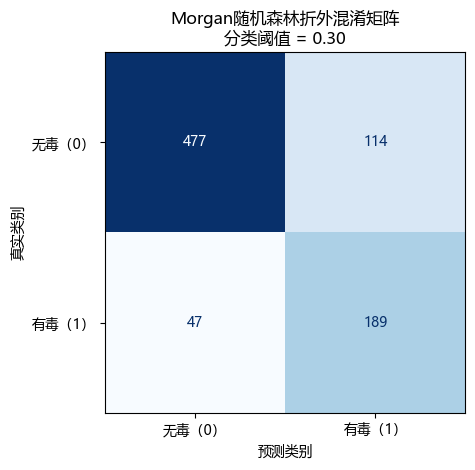

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 使用锁定阈值，把折外概率转换为类别
rf_oof_prediction = (
    rf_oof_probability >= selected_threshold
).astype(int)

# 计算混淆矩阵
rf_oof_confusion_matrix = confusion_matrix(
    y_train,
    rf_oof_prediction,
    labels=[0, 1]
)

# 拆分四种结果
tn, fp, fn, tp = rf_oof_confusion_matrix.ravel()

print("正确识别的无毒样本 TN：", tn)
print("误报为有毒的样本 FP：", fp)
print("漏判的有毒样本 FN：", fn)
print("正确识别的有毒样本 TP：", tp)

# 绘制混淆矩阵
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=rf_oof_confusion_matrix,
    display_labels=[
        "无毒（0）",
        "有毒（1）"
    ]
)

cm_display.plot(
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Morgan随机森林折外混淆矩阵\n"
    f"分类阈值 = {selected_threshold:.2f}"
)
plt.xlabel("预测类别")
plt.ylabel("真实类别")
plt.tight_layout()
plt.show()

In [46]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

# 取出827个训练样本的元数据
scaffold_training_metadata = metadata.loc[
    train_ids
].copy()


def calculate_murcko_scaffold(smiles):
    """
    根据SMILES计算Bemis-Murcko骨架。
    无环分子通常返回空字符串。
    """
    molecule = Chem.MolFromSmiles(smiles)

    if molecule is None:
        return None

    scaffold_smiles = (
        MurckoScaffold.MurckoScaffoldSmiles(
            mol=molecule,
            includeChirality=False
        )
    )

    return scaffold_smiles


# 为每个训练化合物计算骨架
scaffold_training_metadata["murcko_scaffold"] = (
    scaffold_training_metadata["canonical_smiles"]
    .apply(calculate_murcko_scaffold)
)

# 基本质量检查
n_training_samples = len(scaffold_training_metadata)

n_missing_scaffolds = (
    scaffold_training_metadata["murcko_scaffold"]
    .isna()
    .sum()
)

n_acyclic_samples = (
    scaffold_training_metadata["murcko_scaffold"]
    .eq("")
    .sum()
)

n_nonempty_scaffolds = (
    scaffold_training_metadata.loc[
        scaffold_training_metadata["murcko_scaffold"] != "",
        "murcko_scaffold"
    ]
    .nunique()
)

print("训练样本数：", n_training_samples)
print("骨架计算失败数：", n_missing_scaffolds)
print("无环化合物数：", n_acyclic_samples)
print("非空Murcko骨架种类数：", n_nonempty_scaffolds)

print("\n样本数最多的10个骨架：")
display(
    scaffold_training_metadata[
        "murcko_scaffold"
    ]
    .value_counts(dropna=False)
    .head(10)
    .to_frame("化合物数量")
)

训练样本数： 827
骨架计算失败数： 0
无环化合物数： 147
非空Murcko骨架种类数： 357

样本数最多的10个骨架：


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [47]:
from IPython.display import display as notebook_display

scaffold_count_table = (
    scaffold_training_metadata["murcko_scaffold"]
    .value_counts(dropna=False)
    .head(10)
    .rename_axis("Murcko骨架")
    .to_frame("化合物数量")
)

notebook_display(scaffold_count_table)

,化合物数量
Murcko骨架,
,147
c1ccccc1,139
c1ccncc1,17
c1ccc(Oc2ccccc2)cc1,14
c1ncncn1,14
O=C(Nc1ncncn1)NS(=O)(=O)c1ccccc1,11
O=C(OCc1cccc(Oc2ccccc2)c1)C1CC1,9
O=C(Nc1ncccn1)NS(=O)(=O)c1ccccc1,8
c1ccc(Oc2ccccn2)cc1,7


In [48]:
# 汇总每个骨架组的样本数与标签分布
scaffold_group_summary = (
    scaffold_training_metadata
    .groupby(
        "murcko_scaffold",
        dropna=False
    )
    .agg(
        样本数=("label", "size"),
        有毒数量=("label", "sum"),
        有毒比例=("label", "mean")
    )
    .sort_values(
        "样本数",
        ascending=False
    )
    .reset_index()
)

# 让空骨架在表格中更容易辨认
scaffold_group_summary["骨架显示"] = (
    scaffold_group_summary["murcko_scaffold"]
    .replace(
        {
            "": "[无环/空骨架]"
        }
    )
)

# 调整显示列顺序
scaffold_group_summary = scaffold_group_summary[
    [
        "骨架显示",
        "样本数",
        "有毒数量",
        "有毒比例",
        "murcko_scaffold"
    ]
]

# 统计骨架组规模
scaffold_group_sizes = (
    scaffold_training_metadata[
        "murcko_scaffold"
    ]
    .value_counts(dropna=False)
)

print("骨架组总数：", len(scaffold_group_sizes))
print(
    "仅包含1个化合物的骨架组数：",
    (scaffold_group_sizes == 1).sum()
)

print("\n样本数最多的15个骨架组：")
notebook_display(
    scaffold_group_summary
    .head(15)
    .round(
        {
            "有毒比例": 3
        }
    )
)

骨架组总数： 358
仅包含1个化合物的骨架组数： 281

样本数最多的15个骨架组：


,骨架显示,样本数,有毒数量,有毒比例,murcko_scaffold
0,[无环/空骨架],147,53,0.361,
1,c1ccccc1,139,43,0.309,c1ccccc1
2,c1ccncc1,17,3,0.176,c1ccncc1
3,c1ccc(Oc2ccccc2)cc1,14,1,0.071,c1ccc(Oc2ccccc2)cc1
4,c1ncncn1,14,2,0.143,c1ncncn1
5,O=C(Nc1ncncn1)NS(=O)(=O)c1ccccc1,11,3,0.273,O=C(Nc1ncncn1)NS(=O)(=O)c1ccccc1
6,O=C(OCc1cccc(Oc2ccccc2)c1)C1CC1,9,9,1.000,O=C(OCc1cccc(Oc2ccccc2)c1)C1CC1
7,O=C(Nc1ncccn1)NS(=O)(=O)c1ccccc1,8,1,0.125,O=C(Nc1ncccn1)NS(=O)(=O)c1ccccc1
8,O=C1C=CC(OC(=O)C2CC2)C1,7,7,1.000,O=C1C=CC(OC(=O)C2CC2)C1
9,c1ccc(Oc2ccccn2)cc1,7,0,0.000,c1ccc(Oc2ccccn2)cc1


In [49]:
from sklearn.model_selection import StratifiedGroupKFold

# 确保元数据、特征和标签的样本顺序完全一致
assert scaffold_training_metadata.index.equals(
    X_morgan_train.index
)

assert scaffold_training_metadata.index.equals(
    y_train.index
)

# 原始Murcko骨架作为分组编号
raw_scaffold_groups = (
    scaffold_training_metadata["murcko_scaffold"]
)

# 建立骨架分层分组5折
scaffold_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scaffold_fold_records = []

for fold_number, (
    fold_train_positions,
    fold_validation_positions
) in enumerate(
    scaffold_cv.split(
        X_morgan_train,
        y_train,
        groups=raw_scaffold_groups
    ),
    start=1
):
    fold_train_groups = set(
        raw_scaffold_groups.iloc[
            fold_train_positions
        ]
    )

    fold_validation_groups = set(
        raw_scaffold_groups.iloc[
            fold_validation_positions
        ]
    )

    shared_scaffolds = (
        fold_train_groups
        & fold_validation_groups
    )

    fold_y_train = y_train.iloc[
        fold_train_positions
    ]

    fold_y_validation = y_train.iloc[
        fold_validation_positions
    ]

    scaffold_fold_records.append(
        {
            "折数": fold_number,
            "训练样本数": len(fold_train_positions),
            "验证样本数": len(fold_validation_positions),
            "训练集有毒比例_%": (
                fold_y_train.mean() * 100
            ),
            "验证集有毒比例_%": (
                fold_y_validation.mean() * 100
            ),
            "验证集骨架数": len(
                fold_validation_groups
            ),
            "验证集包含无环大组": (
                "" in fold_validation_groups
            ),
            "验证集包含苯环大组": (
                "c1ccccc1"
                in fold_validation_groups
            ),
            "跨越两侧的相同骨架数": len(
                shared_scaffolds
            )
        }
    )

raw_scaffold_fold_summary = (
    pd.DataFrame(scaffold_fold_records)
    .set_index("折数")
)

raw_scaffold_fold_summary.round(2)

,训练样本数,验证样本数,训练集有毒比例_%,验证集有毒比例_%,验证集骨架数,验证集包含无环大组,验证集包含苯环大组,跨越两侧的相同骨架数
折数,,,,,,,,
1,779,48,28.88,22.92,24,False,False,0
2,795,32,28.93,18.75,23,False,False,0
3,522,305,27.97,29.51,107,True,False,0
4,533,294,28.14,29.25,103,False,True,0
5,679,148,28.42,29.05,101,False,False,0


In [50]:
# 搜索划分更加均衡的随机种子
scaffold_seed_records = []

overall_positive_rate = y_train.mean()
target_fold_size = len(y_train) / 5

for candidate_seed in range(200):
    candidate_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=candidate_seed
    )

    validation_sizes = []
    validation_positive_rates = []

    for _, validation_positions in candidate_cv.split(
        X_morgan_train,
        y_train,
        groups=raw_scaffold_groups
    ):
        validation_sizes.append(len(validation_positions))
        validation_positive_rates.append(
            y_train.iloc[validation_positions].mean()
        )

    # 衡量5折样本数偏离理想大小的程度
    size_error = np.mean(
        np.abs(np.array(validation_sizes) - target_fold_size)
    ) / target_fold_size

    # 衡量5折有毒比例偏离总体比例的程度
    label_error = np.mean(
        np.abs(
            np.array(validation_positive_rates)
            - overall_positive_rate
        )
    )

    scaffold_seed_records.append(
        {
            "随机种子": candidate_seed,
            "划分总偏差": size_error + label_error,
            "最小验证集": min(validation_sizes),
            "最大验证集": max(validation_sizes),
            "最低有毒比例_%": (
                min(validation_positive_rates) * 100
            ),
            "最高有毒比例_%": (
                max(validation_positive_rates) * 100
            )
        }
    )

scaffold_seed_search = (
    pd.DataFrame(scaffold_seed_records)
    .sort_values("划分总偏差")
    .reset_index(drop=True)
)

scaffold_seed_search.head(10).round(3)

,随机种子,划分总偏差,最小验证集,最大验证集,最低有毒比例_%,最高有毒比例_%
0,164,0.339,42,278,21.176,34.173
1,125,0.342,56,285,18.792,32.544
2,84,0.350,37,282,25.309,35.135
3,168,0.357,45,296,21.687,33.333
4,7,0.358,46,284,20.112,32.042
5,113,0.358,26,276,23.077,30.072
6,102,0.368,33,307,22.892,30.945
7,65,0.373,40,287,22.500,31.073
8,64,0.373,34,284,23.529,29.930
9,72,0.373,28,291,17.857,32.530


In [51]:
# 比较3折、4折和5折骨架交叉验证的最佳划分
scaffold_cv_option_records = []

for n_splits in [3, 4, 5]:
    target_fold_size = len(y_train) / n_splits

    for candidate_seed in range(200):
        candidate_cv = StratifiedGroupKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=candidate_seed
        )

        validation_sizes = []
        validation_positive_rates = []

        for _, validation_positions in candidate_cv.split(
            X_morgan_train,
            y_train,
            groups=raw_scaffold_groups
        ):
            validation_sizes.append(
                len(validation_positions)
            )
            validation_positive_rates.append(
                y_train.iloc[validation_positions].mean()
            )

        size_error = np.mean(
            np.abs(
                np.array(validation_sizes)
                - target_fold_size
            )
        ) / target_fold_size

        label_error = np.mean(
            np.abs(
                np.array(validation_positive_rates)
                - y_train.mean()
            )
        )

        scaffold_cv_option_records.append(
            {
                "折数": n_splits,
                "随机种子": candidate_seed,
                "划分总偏差": size_error + label_error,
                "最小验证集": min(validation_sizes),
                "最大验证集": max(validation_sizes),
                "最低有毒比例_%": (
                    min(validation_positive_rates) * 100
                ),
                "最高有毒比例_%": (
                    max(validation_positive_rates) * 100
                )
            }
        )

scaffold_cv_options = pd.DataFrame(
    scaffold_cv_option_records
)

# 分别找出3折、4折、5折中偏差最小的方案
best_option_indices = (
    scaffold_cv_options
    .groupby("折数")["划分总偏差"]
    .idxmin()
)

best_scaffold_cv_options = (
    scaffold_cv_options
    .loc[best_option_indices]
    .sort_values("折数")
    .reset_index(drop=True)
)

best_scaffold_cv_options.round(3)



,折数,随机种子,划分总偏差,最小验证集,最大验证集,最低有毒比例_%,最高有毒比例_%
0,3,165,0.128,229,301,27.243,30.640
1,4,26,0.279,104,312,26.066,30.000
2,5,164,0.339,42,278,21.176,34.173


In [52]:
# 锁定最终使用的严格Murcko骨架交叉验证方案
SCAFFOLD_N_SPLITS = 3
SCAFFOLD_RANDOM_STATE = 165

scaffold_cv = StratifiedGroupKFold(
    n_splits=SCAFFOLD_N_SPLITS,
    shuffle=True,
    random_state=SCAFFOLD_RANDOM_STATE
)

scaffold_fold_records = []

for fold_number, (
    fold_train_positions,
    fold_validation_positions
) in enumerate(
    scaffold_cv.split(
        X_morgan_train,
        y_train,
        groups=raw_scaffold_groups
    ),
    start=1
):
    fold_train_groups = set(
        raw_scaffold_groups.iloc[fold_train_positions]
    )
    fold_validation_groups = set(
        raw_scaffold_groups.iloc[fold_validation_positions]
    )

    shared_scaffolds = (
        fold_train_groups & fold_validation_groups
    )

    fold_y_train = y_train.iloc[fold_train_positions]
    fold_y_validation = y_train.iloc[
        fold_validation_positions
    ]

    scaffold_fold_records.append(
        {
            "折数": fold_number,
            "训练样本数": len(fold_train_positions),
            "验证样本数": len(fold_validation_positions),
            "训练集有毒比例_%": (
                fold_y_train.mean() * 100
            ),
            "验证集有毒比例_%": (
                fold_y_validation.mean() * 100
            ),
            "训练集骨架数": len(fold_train_groups),
            "验证集骨架数": len(fold_validation_groups),
            "验证集包含无环大组": (
                "" in fold_validation_groups
            ),
            "验证集包含苯环大组": (
                "c1ccccc1" in fold_validation_groups
            ),
            "跨越两侧的相同骨架数": (
                len(shared_scaffolds)
            )
        }
    )

final_scaffold_fold_summary = (
    pd.DataFrame(scaffold_fold_records)
    .set_index("折数")
)

final_scaffold_fold_summary.round(2)

,训练样本数,验证样本数,训练集有毒比例_%,验证集有毒比例_%,训练集骨架数,验证集骨架数,验证集包含无环大组,验证集包含苯环大组,跨越两侧的相同骨架数
折数,,,,,,,,,
1,526,301,29.28,27.24,245,113,False,True,0
2,530,297,27.36,30.64,248,110,True,False,0
3,598,229,28.93,27.51,223,135,False,False,0


In [53]:
# 使用严格Murcko骨架3折，评价调参后的两个候选模型

scaffold_logistic_cv_results = cross_validate(
    estimator=morgan_logistic_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=raw_scaffold_groups,
    cv=scaffold_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

scaffold_rf_cv_results = cross_validate(
    estimator=morgan_rf_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=raw_scaffold_groups,
    cv=scaffold_cv,
    scoring=scoring_metrics,
    return_train_score=False
)

print("两个模型的严格Murcko骨架3折评价已完成。")

两个模型的严格Murcko骨架3折评价已完成。


In [54]:
# 整理两个模型的Murcko骨架3折结果
scaffold_logistic_summary = summarize_cv_metrics(
    scaffold_logistic_cv_results,
    metric_name_map
)

scaffold_rf_summary = summarize_cv_metrics(
    scaffold_rf_cv_results,
    metric_name_map
)

# 合并为便于比较的表格
scaffold_model_comparison = pd.DataFrame(
    {
        "逻辑回归_3折平均值": (
            scaffold_logistic_summary["平均值"]
        ),
        "逻辑回归_3折标准差": (
            scaffold_logistic_summary["标准差"]
        ),
        "随机森林_3折平均值": (
            scaffold_rf_summary["平均值"]
        ),
        "随机森林_3折标准差": (
            scaffold_rf_summary["标准差"]
        )
    }
)

scaffold_model_comparison.round(3)

,逻辑回归_3折平均值,逻辑回归_3折标准差,随机森林_3折平均值,随机森林_3折标准差
评价指标,,,,
Accuracy,0.824,0.010,0.850,0.030
Balanced Accuracy,0.760,0.043,0.754,0.054
有毒类 Precision,0.738,0.075,0.903,0.035
有毒类 Recall,0.611,0.128,0.530,0.110
ROC-AUC,0.820,0.045,0.825,0.056
Average Precision,0.739,0.074,0.761,0.072
MCC,0.554,0.048,0.613,0.083


In [55]:
# 比较普通指纹分组验证与严格骨架验证

validation_strategy_comparison = pd.DataFrame(
    {
        "逻辑回归_指纹分组5折": (
            tuned_morgan_logistic_summary["平均值"]
        ),
        "逻辑回归_骨架3折": (
            scaffold_logistic_summary["平均值"]
        ),
        "随机森林_指纹分组5折": (
            tuned_morgan_rf_summary["平均值"]
        ),
        "随机森林_骨架3折": (
            scaffold_rf_summary["平均值"]
        )
    }
)

# 骨架验证成绩减去普通分组验证成绩
validation_strategy_comparison[
    "逻辑回归_骨架变化"
] = (
    validation_strategy_comparison[
        "逻辑回归_骨架3折"
    ]
    - validation_strategy_comparison[
        "逻辑回归_指纹分组5折"
    ]
)

validation_strategy_comparison[
    "随机森林_骨架变化"
] = (
    validation_strategy_comparison[
        "随机森林_骨架3折"
    ]
    - validation_strategy_comparison[
        "随机森林_指纹分组5折"
    ]
)

validation_strategy_comparison.round(3)

,逻辑回归_指纹分组5折,逻辑回归_骨架3折,随机森林_指纹分组5折,随机森林_骨架3折,逻辑回归_骨架变化,随机森林_骨架变化
评价指标,,,,,,
Accuracy,0.844,0.824,0.861,0.850,-0.020,-0.011
Balanced Accuracy,0.804,0.760,0.778,0.754,-0.044,-0.024
有毒类 Precision,0.740,0.738,0.898,0.903,-0.002,0.006
有毒类 Recall,0.711,0.611,0.585,0.530,-0.100,-0.055
ROC-AUC,0.858,0.820,0.870,0.825,-0.037,-0.045
Average Precision,0.808,0.739,0.826,0.761,-0.069,-0.065
MCC,0.617,0.554,0.646,0.613,-0.062,-0.033


In [56]:
# 获得严格骨架3折下的随机森林折外预测概率
scaffold_rf_oof_probability = cross_val_predict(
    estimator=morgan_rf_search.best_estimator_,
    X=X_morgan_train,
    y=y_train,
    groups=raw_scaffold_groups,
    cv=scaffold_cv,
    method="predict_proba"
)[:, 1]

print(
    "骨架折外预测概率数量：",
    len(scaffold_rf_oof_probability)
)

print(
    "骨架折外平均预测概率：",
    round(scaffold_rf_oof_probability.mean(), 3)
)

# 只比较提前锁定的0.30和默认的0.50
scaffold_rf_threshold_comparison = (
    evaluate_probability_thresholds(
        y_train,
        scaffold_rf_oof_probability,
        [selected_threshold, 0.50]
    )
)

scaffold_rf_threshold_comparison.insert(
    0,
    "验证方案",
    "Murcko骨架3折"
)

scaffold_rf_threshold_comparison.round(3)

骨架折外预测概率数量： 827
骨架折外平均预测概率： 0.318


,验证方案,阈值,有毒Precision,有毒Recall,无毒Recall,Balanced Accuracy,MCC,预测有毒比例_%
0,Murcko骨架3折,0.3,0.575,0.733,0.783,0.758,0.485,36.397
1,Murcko骨架3折,0.5,0.907,0.538,0.978,0.758,0.622,16.929


In [57]:
from sklearn.base import clone

# 锁定最终分析方案
FINAL_MODEL_NAME = "Morgan随机森林"
FINAL_THRESHOLD = 0.30
FINAL_SELECTION_METRIC = "Average Precision"
FINAL_OPERATING_GOAL = "蜜蜂急性毒性筛查，优先减少有毒化合物漏报"

# 复制最佳模型结构和参数
final_model = clone(
    morgan_rf_search.best_estimator_
)

# 使用全部827个训练样本拟合最终模型
final_model.fit(
    X_morgan_train,
    y_train
)

print("最终模型：", FINAL_MODEL_NAME)
print("最终分类阈值：", FINAL_THRESHOLD)
print("模型选择指标：", FINAL_SELECTION_METRIC)
print("应用目标：", FINAL_OPERATING_GOAL)
print("最终训练样本数：", len(y_train))
print("最终测试样本数：", len(y_test))
print("最终模型已经训练完成，但尚未评价测试集。")

最终模型： Morgan随机森林
最终分类阈值： 0.3
模型选择指标： Average Precision
应用目标： 蜜蜂急性毒性筛查，优先减少有毒化合物漏报
最终训练样本数： 827
最终测试样本数： 208
最终模型已经训练完成，但尚未评价测试集。


In [58]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix
)

# 预测208个最终测试样本属于有毒类的概率
final_test_probability = final_model.predict_proba(
    X_morgan_test
)[:, 1]

# 使用提前锁定的0.30阈值转换为类别
final_test_prediction = (
    final_test_probability >= FINAL_THRESHOLD
).astype(int)

# 计算混淆矩阵中的四个数量
tn, fp, fn, tp = confusion_matrix(
    y_test,
    final_test_prediction,
    labels=[0, 1]
).ravel()

# 无毒类Recall，也称特异度
test_specificity = tn / (tn + fp)

# 整理最终测试指标
final_test_metrics = pd.DataFrame(
    {
        "最终测试值": {
            "测试样本数": len(y_test),
            "真实有毒比例": y_test.mean(),
            "预测有毒比例": final_test_prediction.mean(),
            "分类阈值": FINAL_THRESHOLD,
            "Accuracy": accuracy_score(
                y_test,
                final_test_prediction
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_test,
                final_test_prediction
            ),
            "有毒类Precision": precision_score(
                y_test,
                final_test_prediction,
                zero_division=0
            ),
            "有毒类Recall": recall_score(
                y_test,
                final_test_prediction
            ),
            "无毒类Recall": test_specificity,
            "ROC-AUC": roc_auc_score(
                y_test,
                final_test_probability
            ),
            "Average Precision": average_precision_score(
                y_test,
                final_test_probability
            ),
            "MCC": matthews_corrcoef(
                y_test,
                final_test_prediction
            ),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        }
    }
)

final_test_metrics.round(3)

,最终测试值
测试样本数,208.000
真实有毒比例,0.288
预测有毒比例,0.351
分类阈值,0.300
Accuracy,0.803
Balanced Accuracy,0.792
有毒类Precision,0.630
有毒类Recall,0.767
无毒类Recall,0.818
ROC-AUC,0.832


In [ ]:
from pathlib import Path
import joblib
import sys
import sklearn
import rdkit
import pandas as pd
import numpy as np

# 1. 创建模型保存文件夹
model_directory = Path("saved_models")
model_directory.mkdir(exist_ok=True)

# 2. 定义模型文件路径
model_path = (
    model_directory
    / "apis_tox_morgan_random_forest.joblib"
)

# 3. 把模型和必要信息组合成一个字典
model_bundle = {
    # 已经训练完成的随机森林模型
    "model": final_model,

    # 分类概率达到0.30时判定为有毒
    "classification_threshold": FINAL_THRESHOLD,

    # 模型基本信息
    "model_name": FINAL_MODEL_NAME,
    "selection_metric": FINAL_SELECTION_METRIC,
    "operating_goal": FINAL_OPERATING_GOAL,

    # 输入特征的定义
    "feature_type": "Morgan fingerprint",
    "feature_columns": X_morgan_train.columns.tolist(),

    # 生成Morgan指纹时使用的参数
    "fingerprint_parameters": {
        "radius": 2,
        "fp_size": 2048,
        "include_chirality": True
    },

    # 标签含义
    "label_mapping": {
        0: "无毒",
        1: "有毒"
    },

    # 数据规模记录
    "training_sample_count": len(y_train),
    "test_sample_count": len(y_test),

    # 软件版本，方便以后复现
    "software_versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "rdkit": rdkit.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}

# 4. 保存模型包
joblib.dump(
    model_bundle,
    model_path,
    compress=3
)

# 5. 检查保存结果
print("模型保存成功：", model_path.resolve())
print(
    "文件大小：",
    round(model_path.stat().st_size / 1024**2, 2),
    "MB"
)

In [60]:
# 从硬盘重新加载模型包
loaded_bundle = joblib.load(model_path)

# 从模型包中取出模型和分类阈值
loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["classification_threshold"]

# 使用加载后的模型重新预测测试集概率
loaded_test_probability = loaded_model.predict_proba(
    X_morgan_test
)[:, 1]

# 使用保存的0.30阈值生成类别预测
loaded_test_prediction = (
    loaded_test_probability >= loaded_threshold
).astype(int)

# 检查保存前后的结果是否完全一致
probability_is_equal = np.allclose(
    loaded_test_probability,
    final_test_probability
)

prediction_is_equal = np.array_equal(
    loaded_test_prediction,
    final_test_prediction
)

print("模型名称：", loaded_bundle["model_name"])
print("分类阈值：", loaded_threshold)
print("概率预测一致：", probability_is_equal)
print("类别预测一致：", prediction_is_equal)
print("软件版本：", loaded_bundle["software_versions"])

模型名称： Morgan随机森林
分类阈值： 0.3
概率预测一致： True
类别预测一致： True
软件版本： {'python': '3.10.21', 'scikit_learn': '1.7.1', 'rdkit': '2024.09.6', 'pandas': '2.3.3', 'numpy': '2.2.5'}
